# IMDb dataset: data quality and exploration (PySpark)



## 1. Start Spark

`MAX_ROWS` controls how much data is read:

- `MAX_ROWS = 3000` (default, sample mode) keeps the 3,000 most-voted titles, the episodes of those series, and only the rows of the other files linked to them (ratings, alternative titles, crew, principals and the people they reference). The sample is consistent, so every question has an answer, but it covers popular titles only: counts and percentages are not those of the whole database. However it is runnable on a small laptop with no graphics card in about 45 minutes.
- `MAX_ROWS = -1` (full run) reads every row of every file.

The value can also be set with the `MAX_ROWS` environment variable. Each mode keeps its own Spark files and writes its CSV results to its own folder (`results/sample_3000/` or `results/full/`), so a test run never overwrites the final results.

In [1]:
import os
from pathlib import Path
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pyspark.sql import SparkSession, functions as F

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_DIR = Path("imdb_data")
DATA_DIR.mkdir(exist_ok=True)
SPARK_DATA_DIR = Path(os.environ.get("SPARK_DATA_DIR", "spark_data"))

MAX_ROWS = int(os.environ.get("MAX_ROWS", "3000"))
RUN_NAME = "full" if MAX_ROWS < 0 else f"sample_{MAX_ROWS}"
WORK_DIR = SPARK_DATA_DIR / RUN_NAME
OUTPUT_DIR = Path("results") / RUN_NAME
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SPARK_DRIVER_MEMORY = os.environ.get("SPARK_DRIVER_MEMORY", "4g")

FEATURE_MIN_RUNTIME = 70
SUCCESS_RATING = 7.5
MIN_SUCCESS_VOTES = 1000
CURRENT_YEAR = pd.Timestamp.today().year

spark = (
    SparkSession.builder
    .appName("imdb-data-quality-and-exploration")
    .master("local[*]")
    .config("spark.driver.memory", SPARK_DRIVER_MEMORY)
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.sql.ansi.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print(f"Run mode: {RUN_NAME} (MAX_ROWS = {MAX_ROWS}), results in {OUTPUT_DIR}/")


def scalar(sql):
    return spark.sql(sql).first()[0]


def export(df, filename, n=100):
    pdf = df.toPandas()
    display(pdf.head(n))
    pdf.to_csv(OUTPUT_DIR / filename, index=False)
    return pdf


def save_table(name, sql):
    path = str(WORK_DIR / "clean" / name)
    spark.sql(sql).write.mode("overwrite").parquet(path)
    spark.read.parquet(path).createOrReplaceTempView(name)


spark

Run mode: sample_3000 (MAX_ROWS = 3000), results in results/sample_3000/


## 2. Download the seven IMDb files

In [2]:
BASE_URL = "https://datasets.imdbws.com/"
FILES = [
    "title.basics.tsv.gz",
    "title.ratings.tsv.gz",
    "title.akas.tsv.gz",
    "title.crew.tsv.gz",
    "title.episode.tsv.gz",
    "title.principals.tsv.gz",
    "name.basics.tsv.gz",
]

for filename in FILES:
    path = DATA_DIR / filename
    if not path.exists():
        print(f"Downloading {filename} ...")
        urllib.request.urlretrieve(BASE_URL + filename, path)
    else:
        print(f"Already downloaded: {filename}")

print("Files are ready in:", DATA_DIR.resolve())

Already downloaded: title.basics.tsv.gz
Already downloaded: title.ratings.tsv.gz
Already downloaded: title.akas.tsv.gz
Already downloaded: title.crew.tsv.gz
Already downloaded: title.episode.tsv.gz
Already downloaded: title.principals.tsv.gz
Already downloaded: name.basics.tsv.gz
Files are ready in: /home/jovyan/work/imdb_data


## 3. Load the files into Spark


In [3]:
TABLE_FILES = {
    "title_basics": "title.basics.tsv.gz",
    "title_ratings": "title.ratings.tsv.gz",
    "title_akas": "title.akas.tsv.gz",
    "title_crew": "title.crew.tsv.gz",
    "title_episode": "title.episode.tsv.gz",
    "title_principals": "title.principals.tsv.gz",
    "name_basics": "name.basics.tsv.gz",
}

def read_tsv(table):
    return (spark.read
        .options(sep="\t", header=True, nullValue="\\N", quote="", inferSchema=False)
        .csv(str(DATA_DIR / TABLE_FILES[table])))


def store_raw(table, df):
    target = WORK_DIR / "raw" / table
    if not (target / "_SUCCESS").exists():
        print(f"Converting {TABLE_FILES[table]} to Parquet ...")
        df.write.mode("overwrite").parquet(str(target))
    spark.read.parquet(str(target)).createOrReplaceTempView(table)


def keep(table, ids, column):
    return read_tsv(table).join(F.broadcast(ids.withColumnRenamed("tconst", column)), column, "left_semi")


if MAX_ROWS < 0:
    for table in TABLE_FILES:
        store_raw(table, read_tsv(table))
else:
    top_rows = (read_tsv("title_ratings")
        .orderBy(F.col("numVotes").cast("int").desc_nulls_last(), "tconst")
        .limit(MAX_ROWS).select("tconst").collect())
    top_ids = spark.createDataFrame(top_rows, "tconst string")
    store_raw("title_episode", keep("title_episode", top_ids, "parentTconst")
              .unionByName(keep("title_episode", top_ids, "tconst")).distinct())
    episode_rows = spark.table("title_episode").select("tconst").collect()
    sample_ids = spark.createDataFrame(top_rows + episode_rows, "tconst string").distinct().cache()
    print(f"Sample: {len(top_rows):,} most-voted titles + {len(episode_rows):,} episode rows")
    store_raw("title_basics", keep("title_basics", sample_ids, "tconst"))
    store_raw("title_ratings", keep("title_ratings", sample_ids, "tconst"))
    store_raw("title_akas", keep("title_akas", sample_ids, "titleId"))
    store_raw("title_crew", keep("title_crew", sample_ids, "tconst"))
    store_raw("title_principals", keep("title_principals", sample_ids, "tconst"))
    people_ids = spark.sql('''
        SELECT nconst FROM title_principals
        UNION SELECT explode(split(directors, ',')) FROM title_crew
        UNION SELECT explode(split(writers, ',')) FROM title_crew
    ''').where("nconst IS NOT NULL").distinct().withColumnRenamed("nconst", "tconst").cache()
    store_raw("name_basics", keep("name_basics", people_ids, "nconst"))

raw_counts = {table: spark.table(table).count() for table in TABLE_FILES}
for table, count in raw_counts.items():
    print(f"{table:18s} {count:>12,} rows")

Converting title.episode.tsv.gz to Parquet ...


Sample: 3,000 most-voted titles + 28,031 episode rows


Converting title.basics.tsv.gz to Parquet ...


Converting title.ratings.tsv.gz to Parquet ...


Converting title.akas.tsv.gz to Parquet ...


Converting title.crew.tsv.gz to Parquet ...


Converting title.principals.tsv.gz to Parquet ...


Converting name.basics.tsv.gz to Parquet ...


title_basics             30,998 rows
title_ratings            30,526 rows
title_akas              226,274 rows
title_crew               30,998 rows
title_episode            28,031 rows
title_principals        679,307 rows
name_basics              52,997 rows


# Data preparation

## 4. Percentage of null, missing or empty values per column


In [4]:
null_rows = []

for table in TABLE_FILES:
    df = spark.table(table)
    counters = [F.count(F.lit(1)).alias("__total")] + [
        F.sum(F.when(F.col(c).isNull() | (F.trim(F.col(c)) == ""), 1).otherwise(0)).alias(c)
        for c in df.columns
    ]
    row = df.agg(*counters).first().asDict()
    total = row["__total"]
    for c in df.columns:
        null_rows.append((table, c, total, row[c], round(100 * row[c] / total, 2) if total else None))

null_report = export(  # Percentage of null/missing/empty values for every column of every table
    spark.createDataFrame(null_rows, "table string, column string, total_rows long, missing_rows long, missing_pct double")
    .orderBy(F.desc("missing_pct"), "table", "column"),
    "imdb_null_percentage_by_column.csv",
)

,table,column,total_rows,missing_rows,missing_pct
0,title_basics,endYear,30998,30726,99.12
1,title_akas,attributes,226274,218643,96.63
2,name_basics,deathYear,52997,46962,88.61
3,title_akas,language,226274,166491,73.58
4,title_principals,job,679307,463027,68.16
5,title_principals,characters,679307,351244,51.71
6,name_basics,birthYear,52997,25879,48.83
7,title_akas,types,226274,43810,19.36
8,title_akas,region,226274,31134,13.76
9,title_basics,runtimeMinutes,30998,1468,4.74


### Five columns with the highest percentage of null values

In [5]:
top_5_missing = null_report.nlargest(5, "missing_pct")  # The five columns of the dataset with the highest null percentage
display(top_5_missing)
top_5_missing.to_csv(OUTPUT_DIR / "top_5_missing_columns.csv", index=False)

,table,column,total_rows,missing_rows,missing_pct
0,title_basics,endYear,30998,30726,99.12
1,title_akas,attributes,226274,218643,96.63
2,name_basics,deathYear,52997,46962,88.61
3,title_akas,language,226274,166491,73.58
4,title_principals,job,679307,463027,68.16


## 5. Other data-quality issues

The checks cover impossible or future dates, people credited on titles released before their birth, duplicate primary keys, out-of-range values, inconsistent series metadata, and foreign keys whose parent record is missing.

In [6]:
quality_checks = []

def add_check(category, issue, sql):
    quality_checks.append((category, issue, scalar(sql)))

add_check("Impossible dates", "People with deathYear earlier than birthYear", '''
    SELECT COUNT(*) FROM name_basics
    WHERE CAST(deathYear AS INT) < CAST(birthYear AS INT)
''')
add_check("Impossible dates", "Principals who died before they were born", '''
    SELECT COUNT(DISTINCT p.nconst) FROM title_principals p
    JOIN name_basics n ON n.nconst = p.nconst
    WHERE CAST(n.deathYear AS INT) < CAST(n.birthYear AS INT)
''')
add_check("Impossible dates", f"People with birthYear or deathYear after {CURRENT_YEAR}", f'''
    SELECT COUNT(*) FROM name_basics
    WHERE CAST(birthYear AS INT) > {CURRENT_YEAR} OR CAST(deathYear AS INT) > {CURRENT_YEAR}
''')
add_check("Impossible dates", "Principal credits on titles released before the person's birth (archive footage excluded)", '''
    SELECT COUNT(*) FROM title_principals p
    JOIN name_basics n ON n.nconst = p.nconst
    JOIN title_basics b ON b.tconst = p.tconst
    WHERE p.category NOT IN ('archive_footage', 'archive_sound')
      AND CAST(b.startYear AS INT) < CAST(n.birthYear AS INT)
''')
add_check("Impossible dates", "Titles with endYear earlier than startYear", '''
    SELECT COUNT(*) FROM title_basics
    WHERE CAST(endYear AS INT) < CAST(startYear AS INT)
''')
add_check("Duplicates", "Duplicate title IDs in title_basics", '''
    SELECT COUNT(*) FROM (SELECT tconst FROM title_basics GROUP BY tconst HAVING COUNT(*) > 1) d
''')
add_check("Duplicates", "Duplicate person IDs in name_basics", '''
    SELECT COUNT(*) FROM (SELECT nconst FROM name_basics GROUP BY nconst HAVING COUNT(*) > 1) d
''')
add_check("Invalid values", "Ratings outside 1-10 or not numeric", '''
    SELECT COUNT(*) FROM title_ratings
    WHERE CAST(averageRating AS DOUBLE) IS NULL OR CAST(averageRating AS DOUBLE) NOT BETWEEN 1 AND 10
''')
add_check("Invalid values", "Ratings with negative or non-numeric vote counts", '''
    SELECT COUNT(*) FROM title_ratings
    WHERE CAST(numVotes AS BIGINT) IS NULL OR CAST(numVotes AS BIGINT) < 0
''')
add_check("Invalid values", "Titles with non-positive or non-numeric runtime", '''
    SELECT COUNT(*) FROM title_basics
    WHERE runtimeMinutes IS NOT NULL AND COALESCE(CAST(runtimeMinutes AS INT), 0) <= 0
''')
add_check("Invalid values", "Titles with isAdult not in {0, 1}", '''
    SELECT COUNT(*) FROM title_basics
    WHERE isAdult IS NULL OR isAdult NOT IN ('0', '1')
''')
add_check("Invalid values", "Episodes with non-positive season/episode numbers", '''
    SELECT COUNT(*) FROM title_episode
    WHERE CAST(seasonNumber AS INT) <= 0 OR CAST(episodeNumber AS INT) <= 0
''')
add_check("Inconsistent metadata", "Episodes whose parent is not a TV series or mini-series", '''
    SELECT COUNT(*) FROM title_episode e
    JOIN title_basics b ON b.tconst = e.parentTconst
    WHERE b.titleType NOT IN ('tvSeries', 'tvMiniSeries')
''')
add_check("Missing parent record", "Ratings referencing missing titles", '''
    SELECT COUNT(*) FROM title_ratings r LEFT ANTI JOIN title_basics b ON b.tconst = r.tconst
''')
add_check("Missing parent record", "Alternative titles referencing missing titles", '''
    SELECT COUNT(*) FROM title_akas a LEFT ANTI JOIN title_basics b ON b.tconst = a.titleId
''')
add_check("Missing parent record", "Crew rows referencing missing titles", '''
    SELECT COUNT(*) FROM title_crew c LEFT ANTI JOIN title_basics b ON b.tconst = c.tconst
''')
add_check("Missing parent record", "Director credits referencing missing people", '''
    SELECT COUNT(*) FROM (
        SELECT explode(split(directors, ',')) AS nconst FROM title_crew WHERE directors IS NOT NULL
    ) d LEFT ANTI JOIN name_basics n ON n.nconst = d.nconst
''')
add_check("Missing parent record", "Writer credits referencing missing people", '''
    SELECT COUNT(*) FROM (
        SELECT explode(split(writers, ',')) AS nconst FROM title_crew WHERE writers IS NOT NULL
    ) w LEFT ANTI JOIN name_basics n ON n.nconst = w.nconst
''')
add_check("Missing parent record", "Episode rows referencing missing episode titles", '''
    SELECT COUNT(*) FROM title_episode e LEFT ANTI JOIN title_basics b ON b.tconst = e.tconst
''')
add_check("Missing parent record", "Episodes referencing missing parent series", '''
    SELECT COUNT(*) FROM title_episode e LEFT ANTI JOIN title_basics b ON b.tconst = e.parentTconst
''')
add_check("Missing parent record", "Principals referencing missing titles", '''
    SELECT COUNT(*) FROM title_principals p LEFT ANTI JOIN title_basics b ON b.tconst = p.tconst
''')
add_check("Missing parent record", "Principals referencing missing people", '''
    SELECT COUNT(*) FROM title_principals p LEFT ANTI JOIN name_basics n ON n.nconst = p.nconst
''')
add_check("Missing parent record", "knownForTitles entries referencing missing titles", '''
    SELECT COUNT(*) FROM (
        SELECT explode(split(knownForTitles, ',')) AS tconst FROM name_basics WHERE knownForTitles IS NOT NULL
    ) k LEFT ANTI JOIN title_basics b ON b.tconst = k.tconst
''')

quality_report = export(  # Data-quality issues found in the dataset and number of affected rows
    spark.createDataFrame(quality_checks, "category string, issue string, affected_rows long")
    .orderBy("category", F.desc("affected_rows")),
    "imdb_data_quality_issues.csv",
)

,category,issue,affected_rows
0,Duplicates,Duplicate title IDs in title_basics,0
1,Duplicates,Duplicate person IDs in name_basics,0
2,Impossible dates,Principal credits on titles released before th...,11
3,Impossible dates,People with deathYear earlier than birthYear,2
4,Impossible dates,Principals who died before they were born,1
5,Impossible dates,People with birthYear or deathYear after 2026,0
6,Impossible dates,Titles with endYear earlier than startYear,0
7,Inconsistent metadata,Episodes whose parent is not a TV series or mi...,0
8,Invalid values,Episodes with non-positive season/episode numbers,29
9,Invalid values,Ratings outside 1-10 or not numeric,0


### Examples of the issues

In [7]:
principals_died_before_born = spark.sql(  # Principals who died before they were born
    '''
    SELECT DISTINCT n.nconst, n.primaryName, n.birthYear, n.deathYear
    FROM title_principals p
    JOIN name_basics n ON n.nconst = p.nconst
    WHERE CAST(n.deathYear AS INT) < CAST(n.birthYear AS INT)
    ORDER BY n.primaryName
''').toPandas()
display(principals_died_before_born)

display(spark.sql('''
    SELECT e.* FROM title_episode e
    LEFT ANTI JOIN title_basics b ON b.tconst = e.parentTconst
''').limit(20).toPandas())

display(spark.sql('''
    SELECT p.tconst, b.primaryTitle, b.startYear, p.nconst, n.primaryName, n.birthYear, p.category
    FROM title_principals p
    JOIN name_basics n ON n.nconst = p.nconst
    JOIN title_basics b ON b.tconst = p.tconst
    WHERE p.category NOT IN ('archive_footage', 'archive_sound')
      AND CAST(b.startYear AS INT) < CAST(n.birthYear AS INT)
''').limit(20).toPandas())

,nconst,primaryName,birthYear,deathYear
0,nm0392955,Homer,850,800


,parentTconst,tconst,seasonNumber,episodeNumber


,tconst,primaryTitle,startYear,nconst,primaryName,birthYear,category
0,tt0013442,Nosferatu,1922,nm9991717,Robert Steadman,1965,composer
1,tt0017925,The General,1926,nm0002301,Carl Davis,1936,composer
2,tt0017925,The General,1926,nm0004592,Robert Israel,1963,composer
3,tt0032455,Fantasia,1940,nm0123553,Corey Burton,1955,actor
4,tt0032455,Fantasia,1940,nm0123553,Corey Burton,1955,actor
5,tt0032455,Fantasia,1940,nm0235079,Hugh Douglas,1944,actor
6,tt0032455,Fantasia,1940,nm0235079,Hugh Douglas,1944,actor
7,tt0032455,Fantasia,1940,nm0001513,Tim Matheson,1947,actor
8,tt0032455,Fantasia,1940,nm0001513,Tim Matheson,1947,actor
9,tt0092400,Married... with Children,1987,nm2873311,Lucky,1995,actor


## 6. Handling the data-quality issues

The raw tables are left untouched; cleaned tables are written to Parquet with Spark and used by every analysis below.

| Issue | Handling | Reason |
|---|---|---|
| `\N` / blank strings | Stored as NULL | One consistent representation of "unknown" |
| Non-numeric numbers | `CAST` → NULL | Bad values do not stop the pipeline nor become fake zeros |
| deathYear < birthYear, future birth/death years | Both years set to NULL, `date_issue_flag = true`; the person is kept | We cannot know which year is wrong; dropping the person would orphan all their credits |
| Credits before birth | Kept, flagged with `credit_before_birth` | Often a wrong birthYear; credits are still valid |
| endYear < startYear | endYear set to NULL | startYear is the field used in analyses |
| runtime ≤ 0 | NULL | Excluded from runtime statistics |
| isAdult not 0/1 | NULL | Unknown flag rather than a guess |
| Rating outside 1–10, negative votes | Row removed from `ratings_clean` | Cannot be used in rating analyses |
| Season/episode ≤ 0 | NULL | Episode kept, season unknown |
| Duplicate primary keys | One row kept per key | Keys must be unique for joins |
| Orphan foreign keys | Rows removed from the cleaned child table (`LEFT SEMI JOIN` on the parent; counts kept in the report above) | Inner joins would drop them anyway; this makes it explicit and auditable |

Missing values are never imputed: inventing IDs, dates, ratings or runtimes would fabricate facts.

In [8]:
DATE_ISSUE = f"COALESCE(d < b OR b > {CURRENT_YEAR} OR d > {CURRENT_YEAR}, false)"

save_table("titles_clean", '''
WITH typed AS (
    SELECT tconst, titleType, primaryTitle, originalTitle, isAdult,
           CAST(startYear AS INT) AS startYear,
           CAST(endYear AS INT) AS endYear,
           CAST(runtimeMinutes AS INT) AS runtimeMinutes,
           NULLIF(TRIM(genres), '') AS genres,
           ROW_NUMBER() OVER (PARTITION BY tconst ORDER BY primaryTitle) AS rn
    FROM title_basics
    WHERE tconst IS NOT NULL AND TRIM(tconst) <> ''
)
SELECT tconst, titleType, primaryTitle, originalTitle,
       CASE WHEN isAdult IN ('0', '1') THEN CAST(isAdult AS INT) END AS isAdult,
       startYear,
       CASE WHEN endYear >= startYear OR startYear IS NULL THEN endYear END AS endYear,
       CASE WHEN runtimeMinutes > 0 THEN runtimeMinutes END AS runtimeMinutes,
       genres
FROM typed
WHERE rn = 1
''')

save_table("people_clean", f'''
WITH typed AS (
    SELECT nconst, primaryName, primaryProfession, knownForTitles,
           CAST(birthYear AS INT) AS b, CAST(deathYear AS INT) AS d,
           ROW_NUMBER() OVER (PARTITION BY nconst ORDER BY primaryName) AS rn
    FROM name_basics
    WHERE nconst IS NOT NULL AND TRIM(nconst) <> ''
)
SELECT nconst, primaryName,
       CASE WHEN {DATE_ISSUE} THEN NULL ELSE b END AS birthYear,
       CASE WHEN {DATE_ISSUE} THEN NULL ELSE d END AS deathYear,
       {DATE_ISSUE} AS date_issue_flag,
       primaryProfession, knownForTitles
FROM typed
WHERE rn = 1
''')

save_table("ratings_clean", '''
WITH typed AS (
    SELECT r.tconst,
           CAST(r.averageRating AS DOUBLE) AS averageRating,
           CAST(r.numVotes AS BIGINT) AS numVotes,
           ROW_NUMBER() OVER (PARTITION BY r.tconst ORDER BY CAST(r.numVotes AS BIGINT) DESC) AS rn
    FROM title_ratings r
    LEFT SEMI JOIN titles_clean t ON t.tconst = r.tconst
)
SELECT tconst, averageRating, numVotes
FROM typed
WHERE rn = 1 AND averageRating BETWEEN 1 AND 10 AND numVotes >= 0
''')

save_table("principals_clean", '''
SELECT p.tconst, CAST(p.ordering AS INT) AS ordering, p.nconst, p.category, p.job, p.characters,
       COALESCE(t.startYear < n.birthYear AND p.category NOT IN ('archive_footage', 'archive_sound'), false)
           AS credit_before_birth
FROM title_principals p
JOIN titles_clean t ON t.tconst = p.tconst
JOIN people_clean n ON n.nconst = p.nconst
''')

for role, column in [("directors_clean", "directors"), ("writers_clean", "writers")]:
    save_table(role, f'''
    SELECT DISTINCT c.tconst, c.nconst
    FROM (
        SELECT tconst, explode(split({column}, ',')) AS nconst
        FROM title_crew WHERE {column} IS NOT NULL
    ) c
    LEFT SEMI JOIN titles_clean t ON t.tconst = c.tconst
    LEFT SEMI JOIN people_clean p ON p.nconst = c.nconst
    ''')

save_table("episodes_clean", '''
SELECT e.tconst, e.parentTconst,
       CASE WHEN CAST(e.seasonNumber AS INT) > 0 THEN CAST(e.seasonNumber AS INT) END AS seasonNumber,
       CASE WHEN CAST(e.episodeNumber AS INT) > 0 THEN CAST(e.episodeNumber AS INT) END AS episodeNumber
FROM title_episode e
LEFT SEMI JOIN titles_clean t ON t.tconst = e.tconst
LEFT SEMI JOIN titles_clean s ON s.tconst = e.parentTconst
''')

save_table("akas_clean", '''
SELECT a.titleId AS tconst, CAST(a.ordering AS INT) AS ordering, a.title,
       NULLIF(TRIM(a.region), '') AS region, NULLIF(LOWER(TRIM(a.language)), '') AS language,
       a.types, a.attributes, a.isOriginalTitle = '1' AS isOriginalTitle
FROM title_akas a
LEFT SEMI JOIN titles_clean t ON t.tconst = a.titleId
''')

CLEAN_TABLES = {
    "title_basics": "titles_clean", "name_basics": "people_clean", "title_ratings": "ratings_clean",
    "title_principals": "principals_clean", "title_episode": "episodes_clean", "title_akas": "akas_clean",
}
clean_counts = {clean: spark.table(clean).count() for clean in CLEAN_TABLES.values()}
cleaning_summary = pd.DataFrame([  # Row counts before and after handling the data-quality issues
    {"raw_table": raw, "clean_table": clean, "raw_rows": raw_counts[raw],
     "clean_rows": clean_counts[clean], "removed_rows": raw_counts[raw] - clean_counts[clean]}
    for raw, clean in CLEAN_TABLES.items()
])
display(cleaning_summary)
cleaning_summary.to_csv(OUTPUT_DIR / "imdb_cleaning_summary.csv", index=False)

,raw_table,clean_table,raw_rows,clean_rows,removed_rows
0,title_basics,titles_clean,30998,30998,0
1,name_basics,people_clean,52997,52997,0
2,title_ratings,ratings_clean,30526,30526,0
3,title_principals,principals_clean,679307,679307,0
4,title_episode,episodes_clean,28031,28031,0
5,title_akas,akas_clean,226274,226274,0


### Verification: the issues are no longer present in the cleaned tables

In [9]:
post_cleaning_checks = pd.DataFrame([  # Remaining number of problematic rows after cleaning (all expected to be 0)
    {"check": "deathYear < birthYear", "remaining_rows": scalar("SELECT COUNT(*) FROM people_clean WHERE deathYear < birthYear")},
    {"check": "endYear < startYear", "remaining_rows": scalar("SELECT COUNT(*) FROM titles_clean WHERE endYear < startYear")},
    {"check": "runtime <= 0", "remaining_rows": scalar("SELECT COUNT(*) FROM titles_clean WHERE runtimeMinutes <= 0")},
    {"check": "rating outside 1-10", "remaining_rows": scalar("SELECT COUNT(*) FROM ratings_clean WHERE averageRating NOT BETWEEN 1 AND 10")},
    {"check": "duplicate tconst", "remaining_rows": scalar("SELECT COUNT(*) - COUNT(DISTINCT tconst) FROM titles_clean")},
    {"check": "duplicate nconst", "remaining_rows": scalar("SELECT COUNT(*) - COUNT(DISTINCT nconst) FROM people_clean")},
    {"check": "principals without title", "remaining_rows": scalar(
        "SELECT COUNT(*) FROM principals_clean p LEFT ANTI JOIN titles_clean t ON t.tconst = p.tconst")},
    {"check": "principals without person", "remaining_rows": scalar(
        "SELECT COUNT(*) FROM principals_clean p LEFT ANTI JOIN people_clean n ON n.nconst = p.nconst")},
    {"check": "episodes without parent", "remaining_rows": scalar(
        "SELECT COUNT(*) FROM episodes_clean e LEFT ANTI JOIN titles_clean t ON t.tconst = e.parentTconst")},
    {"check": "season/episode <= 0", "remaining_rows": scalar(
        "SELECT COUNT(*) FROM episodes_clean WHERE seasonNumber <= 0 OR episodeNumber <= 0")},
])
display(post_cleaning_checks)

,check,remaining_rows
0,deathYear < birthYear,0
1,endYear < startYear,0
2,runtime <= 0,0
3,rating outside 1-10,0
4,duplicate tconst,0
5,duplicate nconst,0
6,principals without title,0
7,principals without person,0
8,episodes without parent,0
9,season/episode <= 0,0


# Data exploration

## 7. Feature-length movies with unusual runtimes by genre

A movie can belong to several genres, so it is compared with each of its genres. For every genre we compute the mean runtime and the quartiles, and flag movies outside the 1.5×IQR fences.

In [10]:
runtime_outliers_df = spark.sql(  # Feature-length movies whose runtime is notably different from their genre average
    f'''
WITH feature_movies AS (
    SELECT tconst, primaryTitle, startYear, runtimeMinutes, explode(split(genres, ',')) AS genre
    FROM titles_clean
    WHERE titleType = 'movie' AND runtimeMinutes >= {FEATURE_MIN_RUNTIME} AND genres IS NOT NULL
),
genre_stats AS (
    SELECT genre, COUNT(*) AS genre_movie_count, AVG(runtimeMinutes) AS genre_mean,
           percentile(runtimeMinutes, 0.25) AS q1, percentile(runtimeMinutes, 0.75) AS q3
    FROM feature_movies
    GROUP BY genre
),
fenced AS (
    SELECT f.*, s.genre_mean,
           s.q1 - 1.5 * (s.q3 - s.q1) AS lower_fence,
           s.q3 + 1.5 * (s.q3 - s.q1) AS upper_fence
    FROM feature_movies f JOIN genre_stats s ON s.genre = f.genre
)
SELECT genre, tconst, primaryTitle, startYear, runtimeMinutes,
       ROUND(genre_mean, 1) AS genre_mean,
       ROUND(runtimeMinutes - genre_mean, 1) AS diff_from_mean,
       lower_fence, upper_fence,
       CASE WHEN runtimeMinutes > upper_fence THEN 'longer' ELSE 'shorter' END AS direction
FROM fenced
WHERE runtimeMinutes < lower_fence OR runtimeMinutes > upper_fence
ORDER BY genre, ABS(runtimeMinutes - genre_mean) DESC
''')
runtime_outliers_df.createOrReplaceTempView("runtime_outliers")
runtime_outliers = export(runtime_outliers_df, "feature_length_runtime_outliers_by_genre.csv")

runtime_outlier_summary = spark.sql(  # Number of runtime outliers per genre
    '''
SELECT genre, direction, COUNT(DISTINCT tconst) AS outlier_count,
       FIRST(genre_mean) AS genre_mean, FIRST(lower_fence) AS lower_fence, FIRST(upper_fence) AS upper_fence
FROM runtime_outliers
GROUP BY genre, direction
ORDER BY genre, direction
''').toPandas()
display(runtime_outlier_summary)

,genre,tconst,primaryTitle,startYear,runtimeMinutes,genre_mean,diff_from_mean,lower_fence,upper_fence,direction
0,Action,tt1954470,Gangs of Wasseypur,2012,321,118.9,202.1,67.5,167.5,longer
1,Action,tt33014583,Dhurandhar,2025,214,118.9,95.1,67.5,167.5,longer
2,Action,tt0047478,Seven Samurai,1954,207,118.9,88.1,67.5,167.5,longer
3,Action,tt13751694,Animal,2023,204,118.9,85.1,67.5,167.5,longer
4,Action,tt1757678,Avatar: Fire and Ash,2025,197,118.9,78.1,67.5,167.5,longer
5,Action,tt1630029,Avatar: The Way of Water,2022,192,118.9,73.1,67.5,167.5,longer
6,Action,tt0360717,King Kong,2005,187,118.9,68.1,67.5,167.5,longer
7,Action,tt8178634,RRR,2022,187,118.9,68.1,67.5,167.5,longer
8,Action,tt4154796,Avengers: Endgame,2019,186,118.9,67.1,67.5,167.5,longer
9,Action,tt0213149,Pearl Harbor,2001,183,118.9,64.1,67.5,167.5,longer


,genre,direction,outlier_count,genre_mean,lower_fence,upper_fence
0,Action,longer,19,118.9,67.500,167.500
1,Adventure,longer,15,117.3,55.000,175.000
2,Animation,longer,9,96.2,67.000,123.000
3,Biography,longer,8,131.8,83.500,175.500
4,Comedy,longer,17,106.6,63.500,147.500
5,Crime,longer,21,118.9,66.500,166.500
6,Drama,longer,41,122.8,65.500,173.500
7,Family,longer,1,109.9,55.875,164.875
8,Fantasy,longer,7,118.7,62.500,170.500
9,Film-Noir,shorter,1,100.4,89.750,113.750


## 8. Top three genres per year, 1980–2025

"Top" means most movie titles released that year in the genre. Ties are kept (`RANK`), so a year may show more than three genres. Total IMDb votes and mean rating are also given.

In [11]:
spark.sql('''
WITH movie_genres AS (
    SELECT tconst, startYear AS year, explode(split(genres, ',')) AS genre
    FROM titles_clean
    WHERE titleType = 'movie' AND startYear BETWEEN 1980 AND 2025 AND genres IS NOT NULL
),
year_genre_stats AS (
    SELECT g.year, g.genre,
           COUNT(*) AS movie_count,
           SUM(COALESCE(r.numVotes, 0)) AS total_votes,
           AVG(r.averageRating) AS mean_rating
    FROM movie_genres g
    LEFT JOIN ratings_clean r ON r.tconst = g.tconst
    GROUP BY g.year, g.genre
)
SELECT *, RANK() OVER (PARTITION BY year ORDER BY movie_count DESC) AS genre_rank
FROM year_genre_stats
''').cache().createOrReplaceTempView("year_genres")

top3_genres = export(  # Top three movie genres for each year 1980-2025
    spark.sql("SELECT * FROM year_genres WHERE genre_rank <= 3 ORDER BY year, genre_rank, genre"),
    "top_3_genres_by_year_1980_2025.csv",
)

,year,genre,movie_count,total_votes,mean_rating,genre_rank
0,1980,Adventure,3,1891621,7.800000,1
1,1980,Comedy,3,662329,7.600000,1
2,1980,Drama,3,1956801,8.233333,1
3,1981,Adventure,5,1749147,7.400000,1
4,1981,Action,3,511013,7.133333,2
5,1981,Horror,3,513508,7.100000,2
6,1982,Drama,6,1767005,7.550000,1
7,1982,Adventure,5,1250040,7.380000,2
8,1982,Sci-Fi,5,2205029,7.720000,2
9,1983,Comedy,5,738516,7.400000,1


### Top three genres compared with the other genres

For each year, the top-three group is compared with all the other genres on share of titles, titles per genre, votes per title and mean rating.

,year,genre_group,genre_count,movie_count,total_votes,mean_genre_rating,movie_share_pct,movies_per_genre,votes_per_movie
0,1980,Other genres,9,13,6608336,7.433333,59.090909,1.444444,508333.538462
1,1980,Top 3,3,9,4510751,7.877778,40.909091,3.000000,501194.555556
2,1981,Other genres,6,8,1457296,7.466667,42.105263,1.333333,182162.000000
3,1981,Top 3,3,11,2773668,7.211111,57.894737,3.666667,252151.636364
4,1982,Other genres,12,19,5317735,7.611111,54.285714,1.583333,279880.789474
5,1982,Top 3,3,16,5222074,7.550000,45.714286,5.333333,326379.625000
6,1983,Other genres,6,7,2020788,7.400000,26.923077,1.166667,288684.000000
7,1983,Top 3,5,19,6467145,7.338667,73.076923,3.800000,340376.052632
8,1984,Other genres,10,18,5556203,7.646667,40.909091,1.800000,308677.944444
9,1984,Top 3,4,26,8377249,7.448810,59.090909,6.500000,322201.884615


,genre_group,genre_count,movie_share_pct,movies_per_genre,votes_per_movie,mean_genre_rating
0,Other genres,13.04,52.13,5.53,314206.13,7.14
1,Top 3,3.26,47.87,20.93,314392.81,7.05


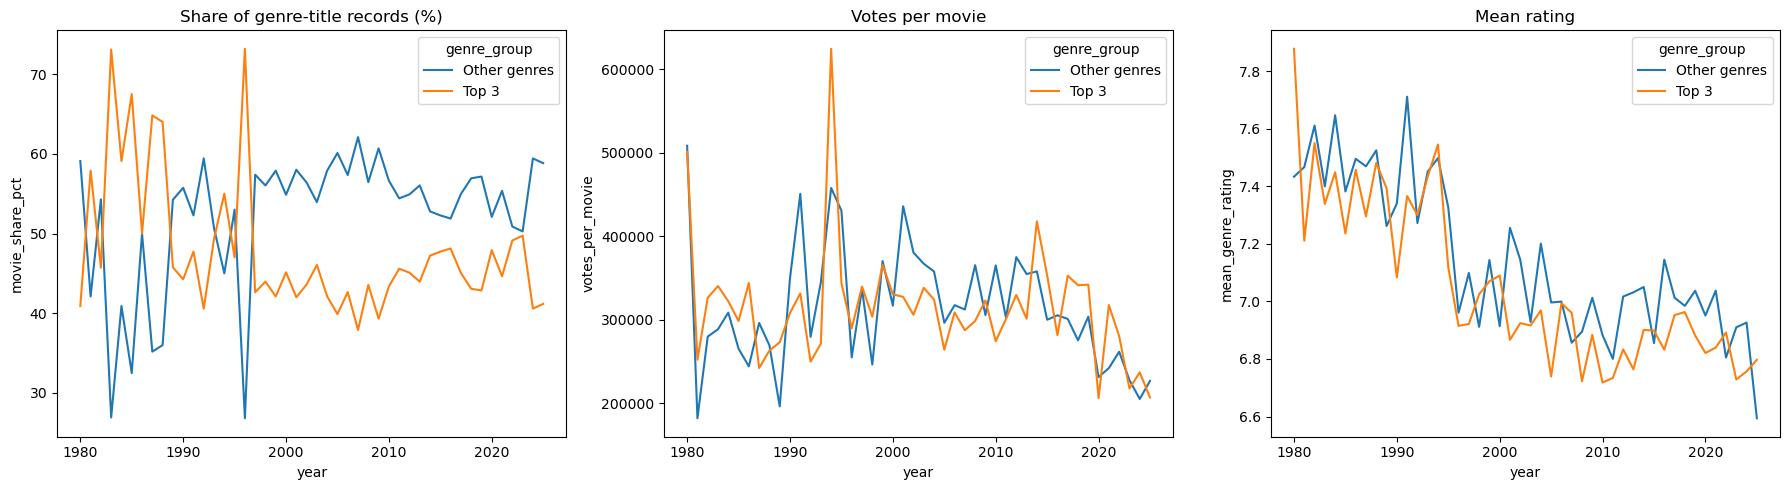

In [12]:
spark.sql('''
WITH grouped AS (
    SELECT year, CASE WHEN genre_rank <= 3 THEN 'Top 3' ELSE 'Other genres' END AS genre_group,
           genre, movie_count, total_votes, mean_rating
    FROM year_genres
),
agg AS (
    SELECT year, genre_group,
           COUNT(DISTINCT genre) AS genre_count,
           SUM(movie_count) AS movie_count,
           SUM(total_votes) AS total_votes,
           AVG(mean_rating) AS mean_genre_rating
    FROM grouped
    GROUP BY year, genre_group
)
SELECT *,
       100 * movie_count / SUM(movie_count) OVER (PARTITION BY year) AS movie_share_pct,
       movie_count / genre_count AS movies_per_genre,
       total_votes / movie_count AS votes_per_movie
FROM agg
ORDER BY year, genre_group
''').createOrReplaceTempView("year_comparison")

year_comparison = export(  # Year-by-year comparison of the top three genres with the other genres
    spark.table("year_comparison"), "top3_vs_other_genres_by_year.csv"
)

overall_comparison = spark.sql(  # Average over 1980-2025 of the top-3 vs other genres comparison
    '''
SELECT genre_group,
       ROUND(AVG(genre_count), 2) AS genre_count,
       ROUND(AVG(movie_share_pct), 2) AS movie_share_pct,
       ROUND(AVG(movies_per_genre), 2) AS movies_per_genre,
       ROUND(AVG(votes_per_movie), 2) AS votes_per_movie,
       ROUND(AVG(mean_genre_rating), 2) AS mean_genre_rating
FROM year_comparison
GROUP BY genre_group
''').toPandas()
display(overall_comparison)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, label in zip(axes, ["movie_share_pct", "votes_per_movie", "mean_genre_rating"],
                             ["Share of genre-title records (%)", "Votes per movie", "Mean rating"]):
    sns.lineplot(data=year_comparison, x="year", y=metric, hue="genre_group", ax=ax)
    ax.set_title(label)
plt.tight_layout()
plt.show()

## 9. Directors with exactly one movie rated ≥ 8.0 and several other movies averaging ≤ 6.0

Each director of a movie gets credit for it. Among the director's rated movies, exactly one must be rated at least 8.0, and the remaining movies (at least two) must have an average rating of at most 6.0.

In [13]:
director_results = export(  # Directors with exactly one movie rated >= 8.0 and multiple other movies averaging <= 6.0
    spark.sql('''
WITH director_movies AS (
    SELECT d.nconst, t.tconst, t.primaryTitle, t.startYear, r.averageRating, r.numVotes
    FROM directors_clean d
    JOIN titles_clean t ON t.tconst = d.tconst AND t.titleType = 'movie'
    JOIN ratings_clean r ON r.tconst = d.tconst
),
director_summary AS (
    SELECT nconst,
           SUM(CASE WHEN averageRating >= 8.0 THEN 1 ELSE 0 END) AS high_movies,
           SUM(CASE WHEN averageRating < 8.0 THEN 1 ELSE 0 END) AS other_movies,
           AVG(CASE WHEN averageRating < 8.0 THEN averageRating END) AS other_movies_avg_rating
    FROM director_movies
    GROUP BY nconst
)
SELECT s.nconst, p.primaryName,
       h.primaryTitle AS high_rated_movie, h.startYear AS high_movie_year,
       h.averageRating AS high_rating, h.numVotes AS high_movie_votes,
       s.other_movies, ROUND(s.other_movies_avg_rating, 2) AS other_movies_avg_rating
FROM director_summary s
JOIN people_clean p ON p.nconst = s.nconst
JOIN director_movies h ON h.nconst = s.nconst AND h.averageRating >= 8.0
WHERE s.high_movies = 1 AND s.other_movies >= 2 AND s.other_movies_avg_rating <= 6.0
ORDER BY h.numVotes DESC
'''),
    "directors_one_high_multiple_low.csv",
)

,nconst,primaryName,high_rated_movie,high_movie_year,high_rating,high_movie_votes,other_movies,other_movies_avg_rating
0,nm0796117,M. Night Shyamalan,The Sixth Sense,1999,8.2,1177664,13,5.98


## 10. TV series: best episode in the first two seasons, worst episode in the last season

Only rated episodes are used. A series qualifies when at least three of its seasons have 10 or more rated episodes. The last season is the highest season number of the series.

In [14]:
series_results = export(  # TV series with >= 3 seasons of >= 10 episodes, worst episode in last season and best in first two
    spark.sql('''
WITH eps AS (
    SELECT e.parentTconst AS series_id, s.primaryTitle AS series_title, e.seasonNumber AS season,
           e.tconst AS episode_id, ep.primaryTitle AS episode_title, r.averageRating, r.numVotes
    FROM episodes_clean e
    JOIN titles_clean s ON s.tconst = e.parentTconst AND s.titleType = 'tvSeries'
    JOIN titles_clean ep ON ep.tconst = e.tconst
    JOIN ratings_clean r ON r.tconst = e.tconst
    WHERE e.seasonNumber IS NOT NULL
),
season_sizes AS (
    SELECT series_id, season, COUNT(*) AS episode_count FROM eps GROUP BY series_id, season
),
eligible AS (
    SELECT series_id,
           SUM(CASE WHEN episode_count >= 10 THEN 1 ELSE 0 END) AS qualifying_seasons,
           MAX(season) AS last_season
    FROM season_sizes
    GROUP BY series_id
    HAVING SUM(CASE WHEN episode_count >= 10 THEN 1 ELSE 0 END) >= 3
),
ranked AS (
    SELECT eps.*, el.qualifying_seasons, el.last_season,
           ROW_NUMBER() OVER (PARTITION BY eps.series_id ORDER BY averageRating DESC, numVotes DESC) AS best_rank,
           ROW_NUMBER() OVER (PARTITION BY eps.series_id ORDER BY averageRating ASC, numVotes DESC) AS worst_rank
    FROM eps JOIN eligible el ON el.series_id = eps.series_id
)
SELECT b.series_id, b.series_title, b.qualifying_seasons, b.last_season,
       b.episode_title AS best_episode, b.season AS best_season, b.averageRating AS best_rating,
       w.episode_title AS worst_episode, w.season AS worst_season, w.averageRating AS worst_rating
FROM ranked b
JOIN ranked w ON w.series_id = b.series_id AND w.worst_rank = 1
WHERE b.best_rank = 1 AND b.season <= 2 AND w.season = w.last_season
ORDER BY b.series_title
'''),
    "series_best_early_worst_last_season.csv",
)

,series_id,series_title,qualifying_seasons,last_season,best_episode,best_season,best_rating,worst_episode,worst_season,worst_rating
0,tt1837492,13 Reasons Why,4,4,"Tape 7, Side A",1,9.2,Senior Camping Trip,4,5.1
1,tt0285331,24,8,8,11:00 p.m.-12:00 a.m.,1,9.3,Day 8: 12:00 a.m.-1:00 a.m.,8,7.6
2,tt6315640,Atypical,3,4,Ernest Shackleton's Rules for Survival,2,9.1,Magical Bird #1,4,7.4
3,tt0934814,Chuck,5,5,Chuck Versus the Ring,2,9.5,Chuck Versus the Bearded Bandit,5,7.4
4,tt8064302,Dead to Me,3,3,You Have to Go,1,8.6,We've Been Here Before,3,7.4
5,tt9335498,Demon Slayer: Kimetsu no Yaiba,3,4,Never Give Up,2,9.8,To Bring a Smile to One's Face,4,7.1
6,tt5296406,Designated Survivor,3,3,The Oath,1,8.5,#makehistory,3,6.5
7,tt0813715,Heroes,4,4,Chapter Twenty 'Five Years Gone',1,8.9,Chapter Fifteen 'Pass/Fail',4,6.8
8,tt1856010,House of Cards,5,6,Chapter 14,2,9.5,Chapter 73,6,2.5
9,tt2357547,Jessica Jones,3,3,A.K.A. Sin Bin,1,9.0,A.K.A. You're Welcome,3,7.1


## 11. Actors/actresses successful in films of several languages

IMDb sets no language on `isOriginalTitle = 1` rows, so the original language of each movie is estimated from the `title.akas` records that carry the original title:

1. explicit `language` values of curated records (non-null `types`; IMDb's untyped records include machine translations), else
2. the main language of the record's country (`region`); multilingual and supranational regions are ignored.

The most frequent language wins. Movies with no evidence are left without a language.

In [15]:
REGION_LANGUAGE = {
    "US": "en", "GB": "en", "AU": "en", "NZ": "en", "IE": "en", "CA": "en",
    "FR": "fr", "DE": "de", "AT": "de", "DDDE": "de", "XWG": "de", "IT": "it",
    "ES": "es", "MX": "es", "AR": "es", "CO": "es", "CL": "es", "PE": "es", "VE": "es", "UY": "es", "CU": "es",
    "BR": "pt", "PT": "pt", "JP": "ja", "KR": "ko", "CN": "zh", "TW": "zh", "HK": "zh",
    "RU": "ru", "SUHH": "ru", "UA": "uk", "PL": "pl", "CZ": "cs", "CSHH": "cs", "SK": "sk",
    "HU": "hu", "RO": "ro", "BG": "bg", "GR": "el", "TR": "tr", "NL": "nl", "SE": "sv",
    "NO": "no", "DK": "da", "FI": "fi", "IS": "is", "IR": "fa", "EG": "ar", "IL": "he",
    "TH": "th", "VN": "vi", "ID": "id", "HR": "hr", "RS": "sr", "SI": "sl", "EE": "et",
    "LV": "lv", "LT": "lt", "GE": "ka", "AM": "hy", "BD": "bn",
}
spark.createDataFrame(list(REGION_LANGUAGE.items()), "region string, language string") \
    .createOrReplaceTempView("region_language")

save_table("movie_language", '''
WITH evidence AS (
    SELECT a.tconst,
           CASE WHEN a.language IS NOT NULL AND a.types IS NOT NULL THEN a.language ELSE rl.language END AS language,
           CASE WHEN a.language IS NOT NULL AND a.types IS NOT NULL THEN 1 ELSE 2 END AS source_priority
    FROM akas_clean a
    JOIN titles_clean t ON t.tconst = a.tconst AND t.titleType = 'movie' AND a.title = t.originalTitle
    LEFT JOIN region_language rl ON rl.region = a.region
    WHERE NOT a.isOriginalTitle
),
votes AS (
    SELECT tconst, language, MIN(source_priority) AS source_priority, COUNT(*) AS n
    FROM evidence WHERE language IS NOT NULL
    GROUP BY tconst, language
),
ranked AS (
    SELECT tconst, language,
           ROW_NUMBER() OVER (PARTITION BY tconst ORDER BY source_priority, n DESC, language) AS rn
    FROM votes
)
SELECT tconst, language FROM ranked WHERE rn = 1
''')

language_success_df = spark.sql(  # Actors/actresses with successful films in at least two distinct languages
    f'''
WITH successful_movies AS (
    SELECT t.tconst, l.language
    FROM titles_clean t
    JOIN ratings_clean r ON r.tconst = t.tconst
    JOIN movie_language l ON l.tconst = t.tconst
    WHERE t.titleType = 'movie'
      AND r.averageRating >= {SUCCESS_RATING}
      AND r.numVotes >= {MIN_SUCCESS_VOTES}
),
actor_language AS (
    SELECT p.nconst, sm.language, COUNT(DISTINCT sm.tconst) AS movies
    FROM principals_clean p
    JOIN successful_movies sm ON sm.tconst = p.tconst
    WHERE p.category IN ('actor', 'actress')
    GROUP BY p.nconst, sm.language
)
SELECT a.nconst, n.primaryName,
       COUNT(*) AS successful_language_count,
       SUM(a.movies) AS successful_movie_count,
       concat_ws(', ', transform(
           sort_array(collect_list(named_struct('k', -a.movies, 'lang', a.language, 'm', a.movies))),
           x -> concat(x.lang, ' (', CAST(x.m AS STRING), ')'))) AS languages
FROM actor_language a
JOIN people_clean n ON n.nconst = a.nconst
GROUP BY a.nconst, n.primaryName
HAVING COUNT(*) >= 2
ORDER BY successful_language_count DESC, successful_movie_count DESC
''')
language_success = export(language_success_df, "actors_successful_in_multiple_languages.csv")

actors_3_languages = export(  # Actors/actresses with successful films in 3 or more languages
    language_success_df.where("successful_language_count >= 3"),
    "actors_successful_in_3_or_more_languages.csv",
)

,nconst,primaryName,successful_language_count,successful_movie_count,languages
0,nm0001884,Max von Sydow,3,5,"en (3), fr (1), sv (1)"
1,nm0504897,Tony Leung Chiu-wai,3,3,"fr (1), ko (1), nl (1)"
2,nm0000093,Brad Pitt,2,19,"en (18), ro (1)"
3,nm0000134,Robert De Niro,2,19,"en (18), it (1)"
4,nm0000151,Morgan Freeman,2,9,"en (8), ro (1)"
5,nm0000228,Kevin Spacey,2,9,"en (8), ro (1)"
6,nm0000246,Bruce Willis,2,9,"en (8), fr (1)"
7,nm0000142,Clint Eastwood,2,8,"en (5), it (3)"
8,nm0000198,Gary Oldman,2,8,"en (7), fr (1)"
9,nm0000582,Joe Pesci,2,8,"en (7), it (1)"


,nconst,primaryName,successful_language_count,successful_movie_count,languages
0,nm0001884,Max von Sydow,3,5,"en (3), fr (1), sv (1)"
1,nm0504897,Tony Leung Chiu-wai,3,3,"fr (1), ko (1), nl (1)"


## 12. Actors/actresses with 20+ year careers, 15+ movies and an early-career peak

Career span runs from the first to the last rated movie in the person's IMDb credits. The midpoint of the span splits the career into early and later halves. The person's best-rated movie must fall in the early half, and the early half's mean rating must exceed the later half's.

In [16]:
early_peak_actors = export(  # Actors/actresses with 20+ years and 15+ movies whose best-rated movies came early in their career
    spark.sql('''
WITH actor_movies AS (
    SELECT DISTINCT p.nconst, t.tconst, t.primaryTitle, t.startYear, r.averageRating, r.numVotes
    FROM principals_clean p
    JOIN titles_clean t ON t.tconst = p.tconst AND t.titleType = 'movie' AND t.startYear IS NOT NULL
    JOIN ratings_clean r ON r.tconst = p.tconst
    WHERE p.category IN ('actor', 'actress')
),
careers AS (
    SELECT nconst, MIN(startYear) AS first_year, MAX(startYear) AS last_year, COUNT(*) AS movie_count
    FROM actor_movies
    GROUP BY nconst
    HAVING COUNT(*) >= 15 AND MAX(startYear) - MIN(startYear) >= 20
),
halves AS (
    SELECT m.*, c.first_year, c.last_year, c.movie_count,
           m.startYear <= (c.first_year + c.last_year) / 2.0 AS is_early
    FROM actor_movies m JOIN careers c ON c.nconst = m.nconst
),
best AS (
    SELECT * FROM (
        SELECT h.*, ROW_NUMBER() OVER (PARTITION BY nconst ORDER BY averageRating DESC, numVotes DESC) AS rn
        FROM halves h
    ) x WHERE rn = 1
),
means AS (
    SELECT nconst,
           AVG(CASE WHEN is_early THEN averageRating END) AS early_mean_rating,
           AVG(CASE WHEN NOT is_early THEN averageRating END) AS later_mean_rating
    FROM halves GROUP BY nconst
)
SELECT b.nconst, n.primaryName AS actor, b.first_year AS first_movie_year, b.last_year AS last_movie_year,
       b.last_year - b.first_year AS career_span_years, b.movie_count,
       b.primaryTitle AS best_movie, b.startYear AS best_movie_year, b.averageRating AS best_movie_rating,
       ROUND(m.early_mean_rating, 2) AS early_mean_rating, ROUND(m.later_mean_rating, 2) AS later_mean_rating
FROM best b
JOIN means m ON m.nconst = b.nconst
JOIN people_clean n ON n.nconst = b.nconst
WHERE b.is_early AND m.early_mean_rating > m.later_mean_rating
ORDER BY b.movie_count DESC, career_span_years DESC
'''),
    "actors_early_career_peak.csv",
)

,nconst,actor,first_movie_year,last_movie_year,career_span_years,movie_count,best_movie,best_movie_year,best_movie_rating,early_mean_rating,later_mean_rating
0,nm0000168,Samuel L. Jackson,1992,2023,31,40,Pulp Fiction,1994,8.8,7.11,6.87
1,nm0000134,Robert De Niro,1973,2023,50,39,The Godfather Part II,1974,9.0,7.87,6.83
2,nm0000093,Brad Pitt,1991,2025,34,39,Fight Club,1999,8.8,7.45,7.21
3,nm0000158,Tom Hanks,1988,2026,38,37,Forrest Gump,1994,8.8,7.54,7.19
4,nm0000353,Willem Dafoe,1986,2024,38,34,Finding Nemo,2003,8.2,7.37,7.13
5,nm0000354,Matt Damon,1997,2026,29,34,Saving Private Ryan,1998,8.6,7.33,7.09
6,nm0000246,Bruce Willis,1988,2019,31,31,Pulp Fiction,1994,8.8,7.36,6.85
7,nm0000151,Morgan Freeman,1989,2019,30,31,The Shawshank Redemption,1994,9.3,7.49,6.93
8,nm0000243,Denzel Washington,1989,2024,35,29,Training Day,2001,7.8,7.35,6.86
9,nm0000242,Mark Wahlberg,1995,2022,27,29,The Departed,2006,8.5,6.75,6.60


## 13. Multi-talented film professionals and same-project performance

Director and writer credits come from `title.crew`; acting credits come from `title.principals`. A person is **multi-talented** when they have credits in at least two of the roles actor, director and writer across their movies. For these people, movies where they held several roles are compared with movies where they held only one.

In [17]:
save_table("project_roles", '''
WITH all_roles AS (
    SELECT tconst, nconst, 'director' AS role FROM directors_clean
    UNION
    SELECT tconst, nconst, 'writer' AS role FROM writers_clean
    UNION
    SELECT tconst, nconst, 'actor' AS role FROM principals_clean WHERE category IN ('actor', 'actress')
)
SELECT a.tconst, a.nconst, t.primaryTitle, t.startYear, r.averageRating, r.numVotes,
       COUNT(*) AS role_count,
       concat_ws(' + ', array_sort(collect_list(a.role))) AS role_combination,
       MAX(CASE WHEN a.role = 'actor' THEN 1 ELSE 0 END) AS acted,
       MAX(CASE WHEN a.role = 'director' THEN 1 ELSE 0 END) AS directed,
       MAX(CASE WHEN a.role = 'writer' THEN 1 ELSE 0 END) AS wrote
FROM all_roles a
JOIN titles_clean t ON t.tconst = a.tconst AND t.titleType = 'movie'
JOIN ratings_clean r ON r.tconst = a.tconst
GROUP BY a.tconst, a.nconst, t.primaryTitle, t.startYear, r.averageRating, r.numVotes
''')

save_table("multi_talented", '''
SELECT * FROM (
    SELECT pr.nconst, p.primaryName,
           MAX(acted) + MAX(directed) + MAX(wrote) AS distinct_role_count,
           MAX(acted) = 1 AS has_acted, MAX(directed) = 1 AS has_directed, MAX(wrote) = 1 AS has_written,
           COUNT(*) AS movie_count,
           SUM(CASE WHEN role_count >= 2 THEN 1 ELSE 0 END) AS multi_role_movies,
           ROUND(AVG(CASE WHEN role_count >= 2 THEN averageRating END), 2) AS multi_role_mean_rating,
           ROUND(AVG(CASE WHEN role_count = 1 THEN averageRating END), 2) AS single_role_mean_rating
    FROM project_roles pr
    JOIN people_clean p ON p.nconst = pr.nconst
    GROUP BY pr.nconst, p.primaryName
) x
WHERE distinct_role_count >= 2
''')

multi_talented = export(  # Multi-talented film professionals (at least two of actor/director/writer)
    spark.sql("SELECT * FROM multi_talented ORDER BY distinct_role_count DESC, multi_role_movies DESC, movie_count DESC"),
    "multi_talented_film_professionals.csv",
)

performance_comparison = export(  # Ratings and votes of multi-talented people: several roles vs one role on the same movie
    spark.sql('''
SELECT CASE WHEN role_count >= 2 THEN 'Multiple roles on same movie' ELSE 'One role' END AS role_group,
       COUNT(*) AS credits, COUNT(DISTINCT tconst) AS movies,
       ROUND(AVG(averageRating), 3) AS mean_rating, percentile(averageRating, 0.5) AS median_rating,
       ROUND(AVG(numVotes), 0) AS mean_votes, percentile(numVotes, 0.5) AS median_votes
FROM project_roles pr
LEFT SEMI JOIN multi_talented m ON m.nconst = pr.nconst
GROUP BY CASE WHEN role_count >= 2 THEN 'Multiple roles on same movie' ELSE 'One role' END
'''),
    "same_project_multiple_roles_performance.csv",
)

role_combinations = export(  # Performance of multi-talented people by combination of roles held on the same movie
    spark.sql('''
SELECT role_combination, COUNT(*) AS credits,
       ROUND(AVG(averageRating), 3) AS mean_rating, percentile(averageRating, 0.5) AS median_rating,
       percentile(numVotes, 0.5) AS median_votes
FROM project_roles pr
LEFT SEMI JOIN multi_talented m ON m.nconst = pr.nconst
GROUP BY role_combination
ORDER BY credits DESC
'''),
    "role_combinations.csv",
)

paired_comparison = export(  # Within-person comparison: does the same person do better when holding several roles?
    spark.sql('''
SELECT COUNT(*) AS people_with_both_kinds_of_movies,
       ROUND(100 * AVG(CASE WHEN multi_role_mean_rating > single_role_mean_rating THEN 1 ELSE 0 END), 2)
           AS pct_better_with_multiple_roles,
       ROUND(100 * AVG(CASE WHEN multi_role_mean_rating < single_role_mean_rating THEN 1 ELSE 0 END), 2)
           AS pct_worse_with_multiple_roles,
       ROUND(AVG(multi_role_mean_rating - single_role_mean_rating), 3) AS mean_rating_difference
FROM multi_talented
WHERE multi_role_mean_rating IS NOT NULL AND single_role_mean_rating IS NOT NULL
'''),
    "multi_role_within_person_comparison.csv",
)

,nconst,primaryName,distinct_role_count,has_acted,has_directed,has_written,movie_count,multi_role_movies,multi_role_mean_rating,single_role_mean_rating
0,nm0000230,Sylvester Stallone,3,True,True,True,26,17,6.77,6.63
1,nm0796117,M. Night Shyamalan,3,True,True,True,16,14,6.14,6.15
2,nm0000233,Quentin Tarantino,3,True,True,True,16,13,7.80,7.40
3,nm0868219,Guillermo del Toro,3,True,True,True,14,9,7.20,7.26
4,nm0736622,Seth Rogen,3,True,True,True,27,7,6.46,6.89
5,nm0000601,Harold Ramis,3,True,True,True,12,7,6.77,6.92
6,nm1191481,Leigh Whannell,3,True,True,True,9,7,6.84,6.40
7,nm0003620,Kevin Smith,3,True,True,True,8,7,7.11,7.10
8,nm0000255,Ben Affleck,3,True,True,True,24,6,7.65,6.77
9,nm0000416,Terry Gilliam,3,True,True,True,8,6,7.58,6.95


,role_group,credits,movies,mean_rating,median_rating,mean_votes,median_votes
0,Multiple roles on same movie,1563,1320,7.139,7.2,327606.0,216806.0
1,One role,2545,1465,6.926,6.9,361613.0,245007.0


,role_combination,credits,mean_rating,median_rating,median_votes
0,director + writer,1254,7.142,7.20,216071.5
1,actor,1243,6.934,7.00,240133.0
2,writer,738,6.875,6.90,247626.5
3,director,564,6.975,7.00,254870.0
4,actor + writer,193,7.028,7.00,208581.0
5,actor + director + writer,78,7.324,7.35,238112.0
6,actor + director,38,7.205,7.30,200758.0


,people_with_both_kinds_of_movies,pct_better_with_multiple_roles,pct_worse_with_multiple_roles,mean_rating_difference
0,464,55.17,43.53,0.112


## 14. Summary and exported files

The notebook writes the following CSV files to `results/full/` (full run) or `results/sample_<MAX_ROWS>/` (test run):

- `imdb_null_percentage_by_column.csv`
- `top_5_missing_columns.csv`
- `imdb_data_quality_issues.csv`
- `imdb_cleaning_summary.csv`
- `feature_length_runtime_outliers_by_genre.csv`
- `top_3_genres_by_year_1980_2025.csv`
- `top3_vs_other_genres_by_year.csv`
- `directors_one_high_multiple_low.csv`
- `series_best_early_worst_last_season.csv`
- `actors_successful_in_multiple_languages.csv`
- `actors_successful_in_3_or_more_languages.csv`
- `actors_early_career_peak.csv`
- `multi_talented_film_professionals.csv`
- `same_project_multiple_roles_performance.csv`
- `role_combinations.csv`
- `multi_role_within_person_comparison.csv`
